<a href="https://colab.research.google.com/github/farhadshajahn5011-maker/ShelfSense-Retail-Shelf-Detection/blob/main/ShelfSense_YOLOv8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🛒 ShelfSense v2 — Retail Shelf Product & Empty-Space Detection (YOLOv8)

**Why v2?** v1 was trained on a tiny bottles-only dataset, so it missed cartons, cans and other packs (domain shift),
and it could not see fully empty shelves.

**v2 uses two YOLOv8 models:**
| Model | Dataset | Detects |
|---|---|---|
| **Product detector** | SKU-110K (CVPR 2019, 11,743 real shelf images) | *any* product — bottles, cans, cartons, boxes |
| **Empty-space detector** | Policenta Empty-Shelf (1,050 images) | empty shelf areas |

Combined output: product count, empty slots, **shelf occupancy %**, and stock status.

> `Runtime → Change runtime type → T4 GPU` before running.

## 1. Setup

In [ ]:
!pip install -q ultralytics roboflow gradio
import os, glob, random, collections, cv2, numpy as np, matplotlib.pyplot as plt, torch
from ultralytics import YOLO
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NOT AVAILABLE — switch to T4 GPU")

from google.colab import drive
drive.mount('/content/drive')
SAVE = "/content/drive/MyDrive/ShelfSense_v2"
os.makedirs(SAVE, exist_ok=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU: Tesla T4
Mounted at /content/drive


## 2. Model A — Product detector on SKU-110K
SKU-110K downloads automatically (~13.6 GB, ~10–15 min the first time).
We train on **20 %** of the training set so it fits in a Colab session (~45–60 min on a T4).
Increase `fraction` / `epochs` if you have more time — accuracy improves.

In [ ]:
prod_model = YOLO("yolov8s.pt")
prod_model.train(
    data="SKU-110K.yaml",
    epochs=25,
    imgsz=640,
    batch=16,
    fraction=0.20,      # 20% of 8,219 train images
    patience=8,
    project="shelfsense", name="products", exist_ok=True,
)
PROD_DIR = str(prod_model.trainer.save_dir)
PROD_BEST = str(prod_model.trainer.best)
!cp -r "{PROD_DIR}" "{SAVE}/"
print("Saved:", PROD_BEST)

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=SKU-110K.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.2, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=products, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overl

## 3. Model B — Empty-space detector
Uses the Policenta *Empty shelf detection* dataset from Roboflow Universe.
⚠️ Remove your API key before sharing this notebook.

In [ ]:
from roboflow import Roboflow
ROBOFLOW_API_KEY = "YOUR ROBOFLOW API KEY"
rf = Roboflow(api_key=ROBOFLOW_API_KEY)
empty_ds = rf.workspace("WORKSPACE").project("PROJECT").version(4).download("yolov8")
EMPTY_YAML = f"{empty_ds.location}/data.yaml"

empty_model = YOLO("yolov8s.pt")
empty_model.train(
    data=EMPTY_YAML, epochs=50, imgsz=640, batch=16, patience=12,
    project="shelfsense", name="empty_space", exist_ok=True,
)
EMPTY_DIR = str(empty_model.trainer.save_dir)
EMPTY_BEST = str(empty_model.trainer.best)
!cp -r "{EMPTY_DIR}" "{SAVE}/"
print("Saved:", EMPTY_BEST)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to bottle-on-shelves-4 in yolov8:: 100%|██████████| 312/312 [00:00<00:00, 6922.65it/s]


Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/bottle-on-shelves-4/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=empty_space, nbs=64, nms=None, opset=None, optimize=

### (Resume here after a disconnect) Load saved models from Drive
Run section 1, then this cell — no retraining needed.

In [ ]:
!pip install -q ultralytics gradio
import os, glob, random, collections, cv2, numpy as np, matplotlib.pyplot as plt
from ultralytics import YOLO
from google.colab import drive
drive.mount('/content/drive')

SAVE = "/content/drive/MyDrive/ShelfSense_v2"
print(glob.glob(f"{SAVE}/*/weights/best.pt"))   # should list 2 files

PROD_BEST  = f"{SAVE}/products/weights/best.pt"
EMPTY_BEST = f"{SAVE}/empty_space/weights/best.pt"
PROD_DIR, EMPTY_DIR = f"{SAVE}/products", f"{SAVE}/empty_space"

prod_model  = YOLO(PROD_BEST)
empty_model = YOLO(EMPTY_BEST)
print("Both models loaded ✅")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Mounted at /content/drive
['/content/drive/MyDrive/ShelfSense_v2/products/weights/best.pt', '/content/drive/MyDrive/ShelfSense_v2/empty_space/weights/best.pt']
Both models loaded ✅


## 4. Evaluate both models

In [ ]:
!pip install -q ultralytics roboflow
from google.colab import drive
drive.mount('/content/drive')
from ultralytics import YOLO
import os

SAVE = "/content/drive/MyDrive/ShelfSense_v2"
p = f"{SAVE}/empty_space/weights/best.pt"
print("Exists:", os.path.exists(p))
if os.path.exists(p):
    print("Classes:", YOLO(p).names)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Exists: True
Classes: {0: 'Void'}


In [ ]:
import glob, random, shutil
from google.colab import files
from roboflow import Roboflow

ds_dir = "/content/Empty-shelf-detection-15"
if not os.path.exists(ds_dir):
    rf = Roboflow(api_key="YOUR ROBOFLOW API KEY")
    ds_dir = rf.workspace("WORKSPACE").project("PROJECT").version(15).download("yolov8").location

imgs = glob.glob(f"{ds_dir}/test/images/*") or glob.glob(f"{ds_dir}/valid/images/*")
os.makedirs("sample_images", exist_ok=True)
for img in random.sample(imgs, min(10, len(imgs))):
    shutil.copy(img, "sample_images/")
shutil.make_archive("sample_images", "zip", "sample_images")
files.download("sample_images.zip")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Empty-shelf-detection-15 in yolov8:: 100%|██████████| 2102/2102 [00:00<00:00, 4253.29it/s]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

=== Product detector (SKU-110K) — best epoch 25 ===
mAP@0.5      : 0.897
mAP@0.5:0.95 : 0.545
Precision    : 0.897
Recall       : 0.837

results.png


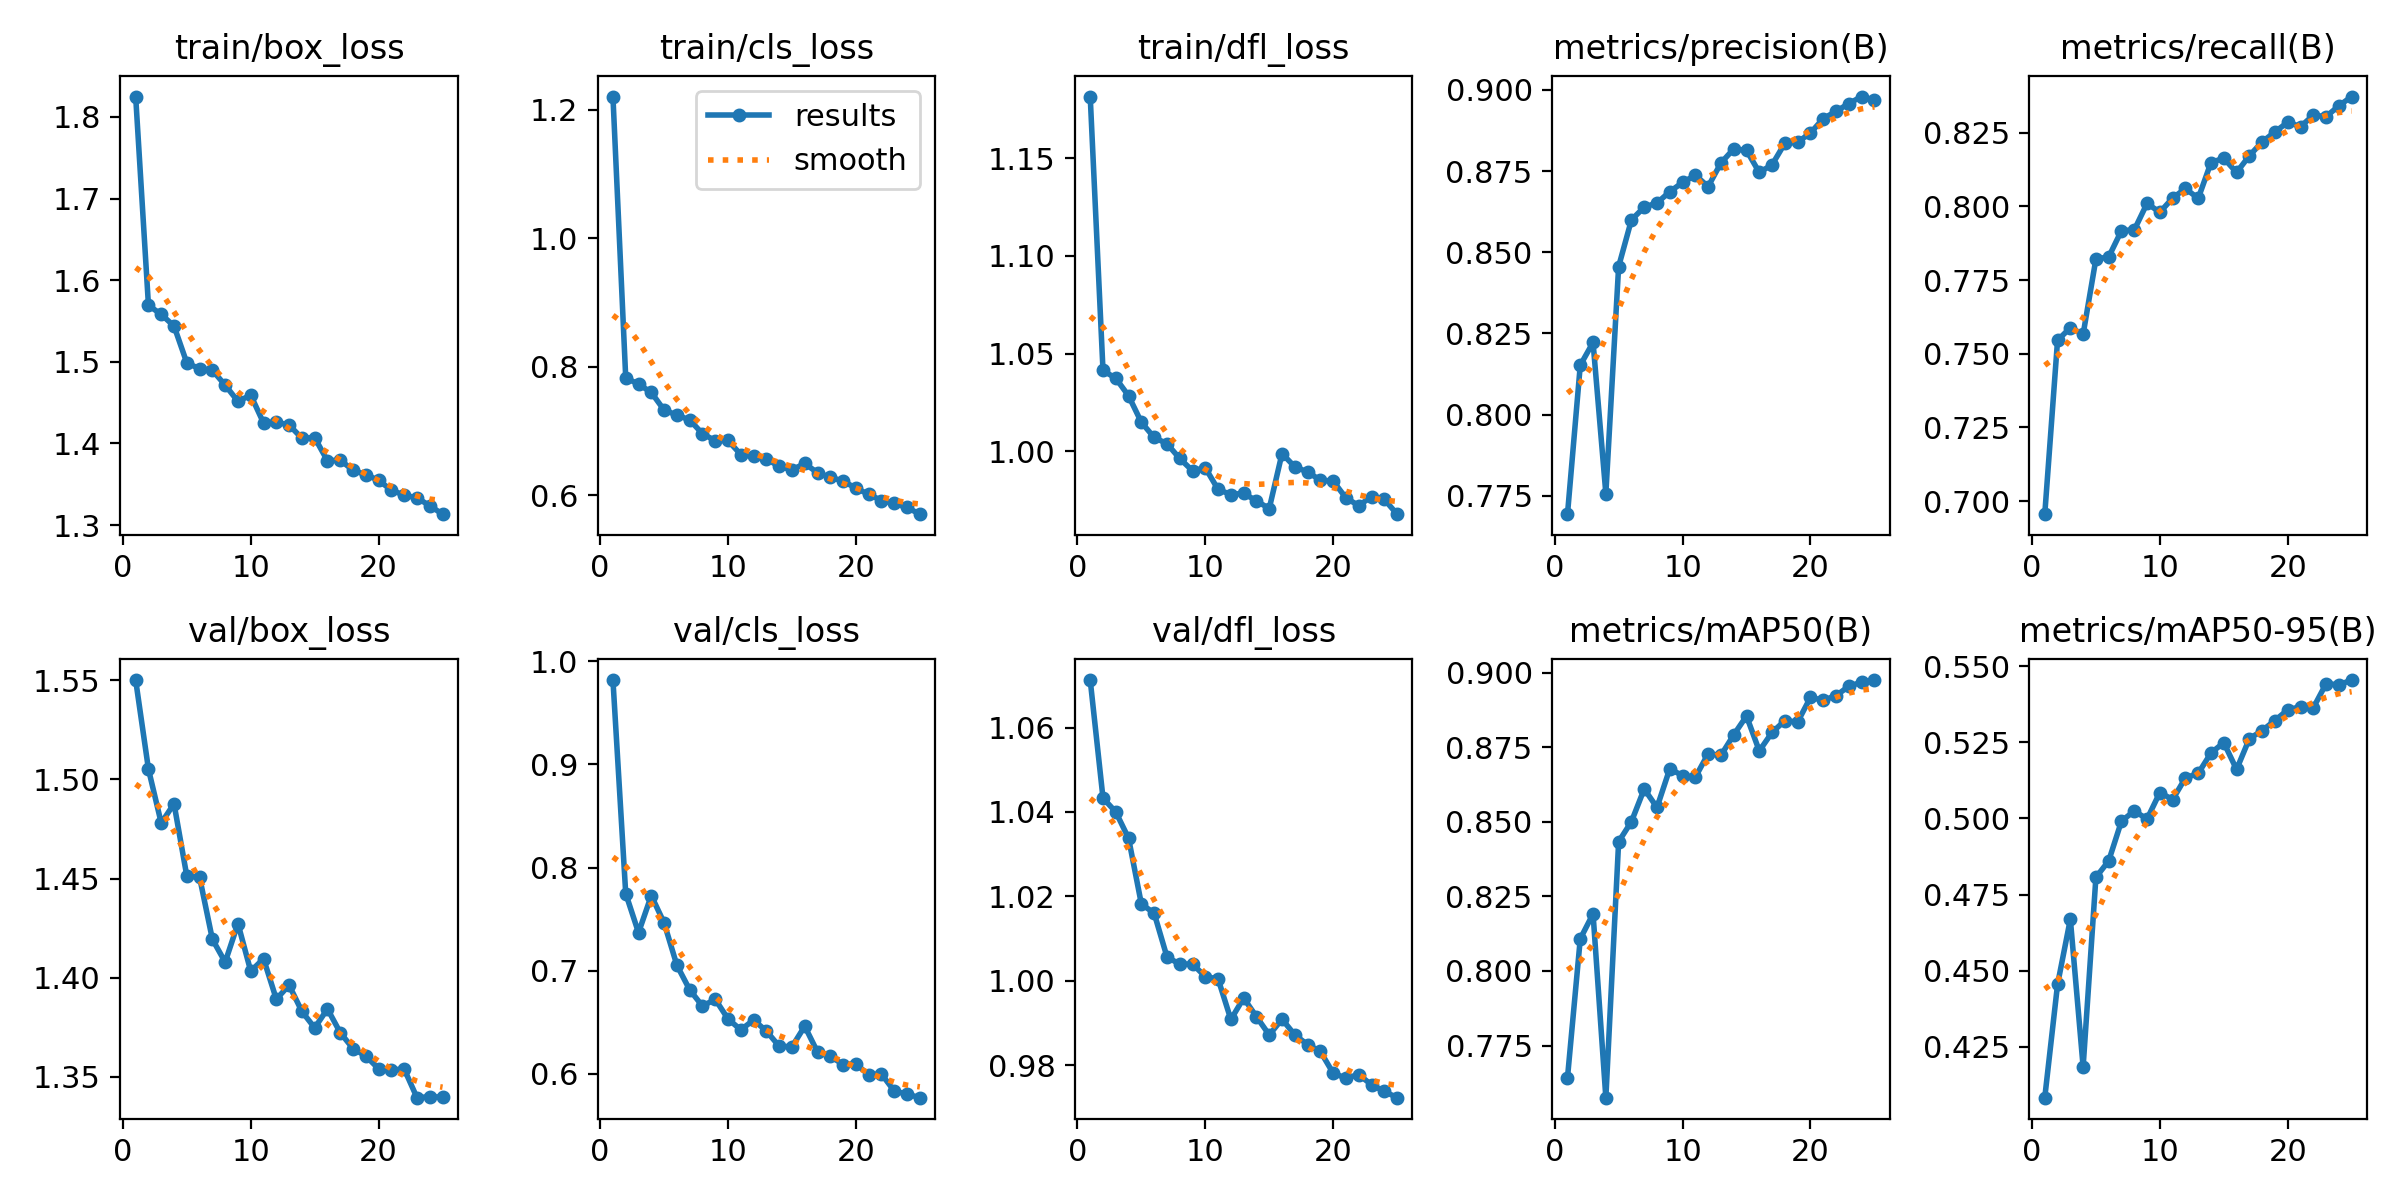

confusion_matrix.png


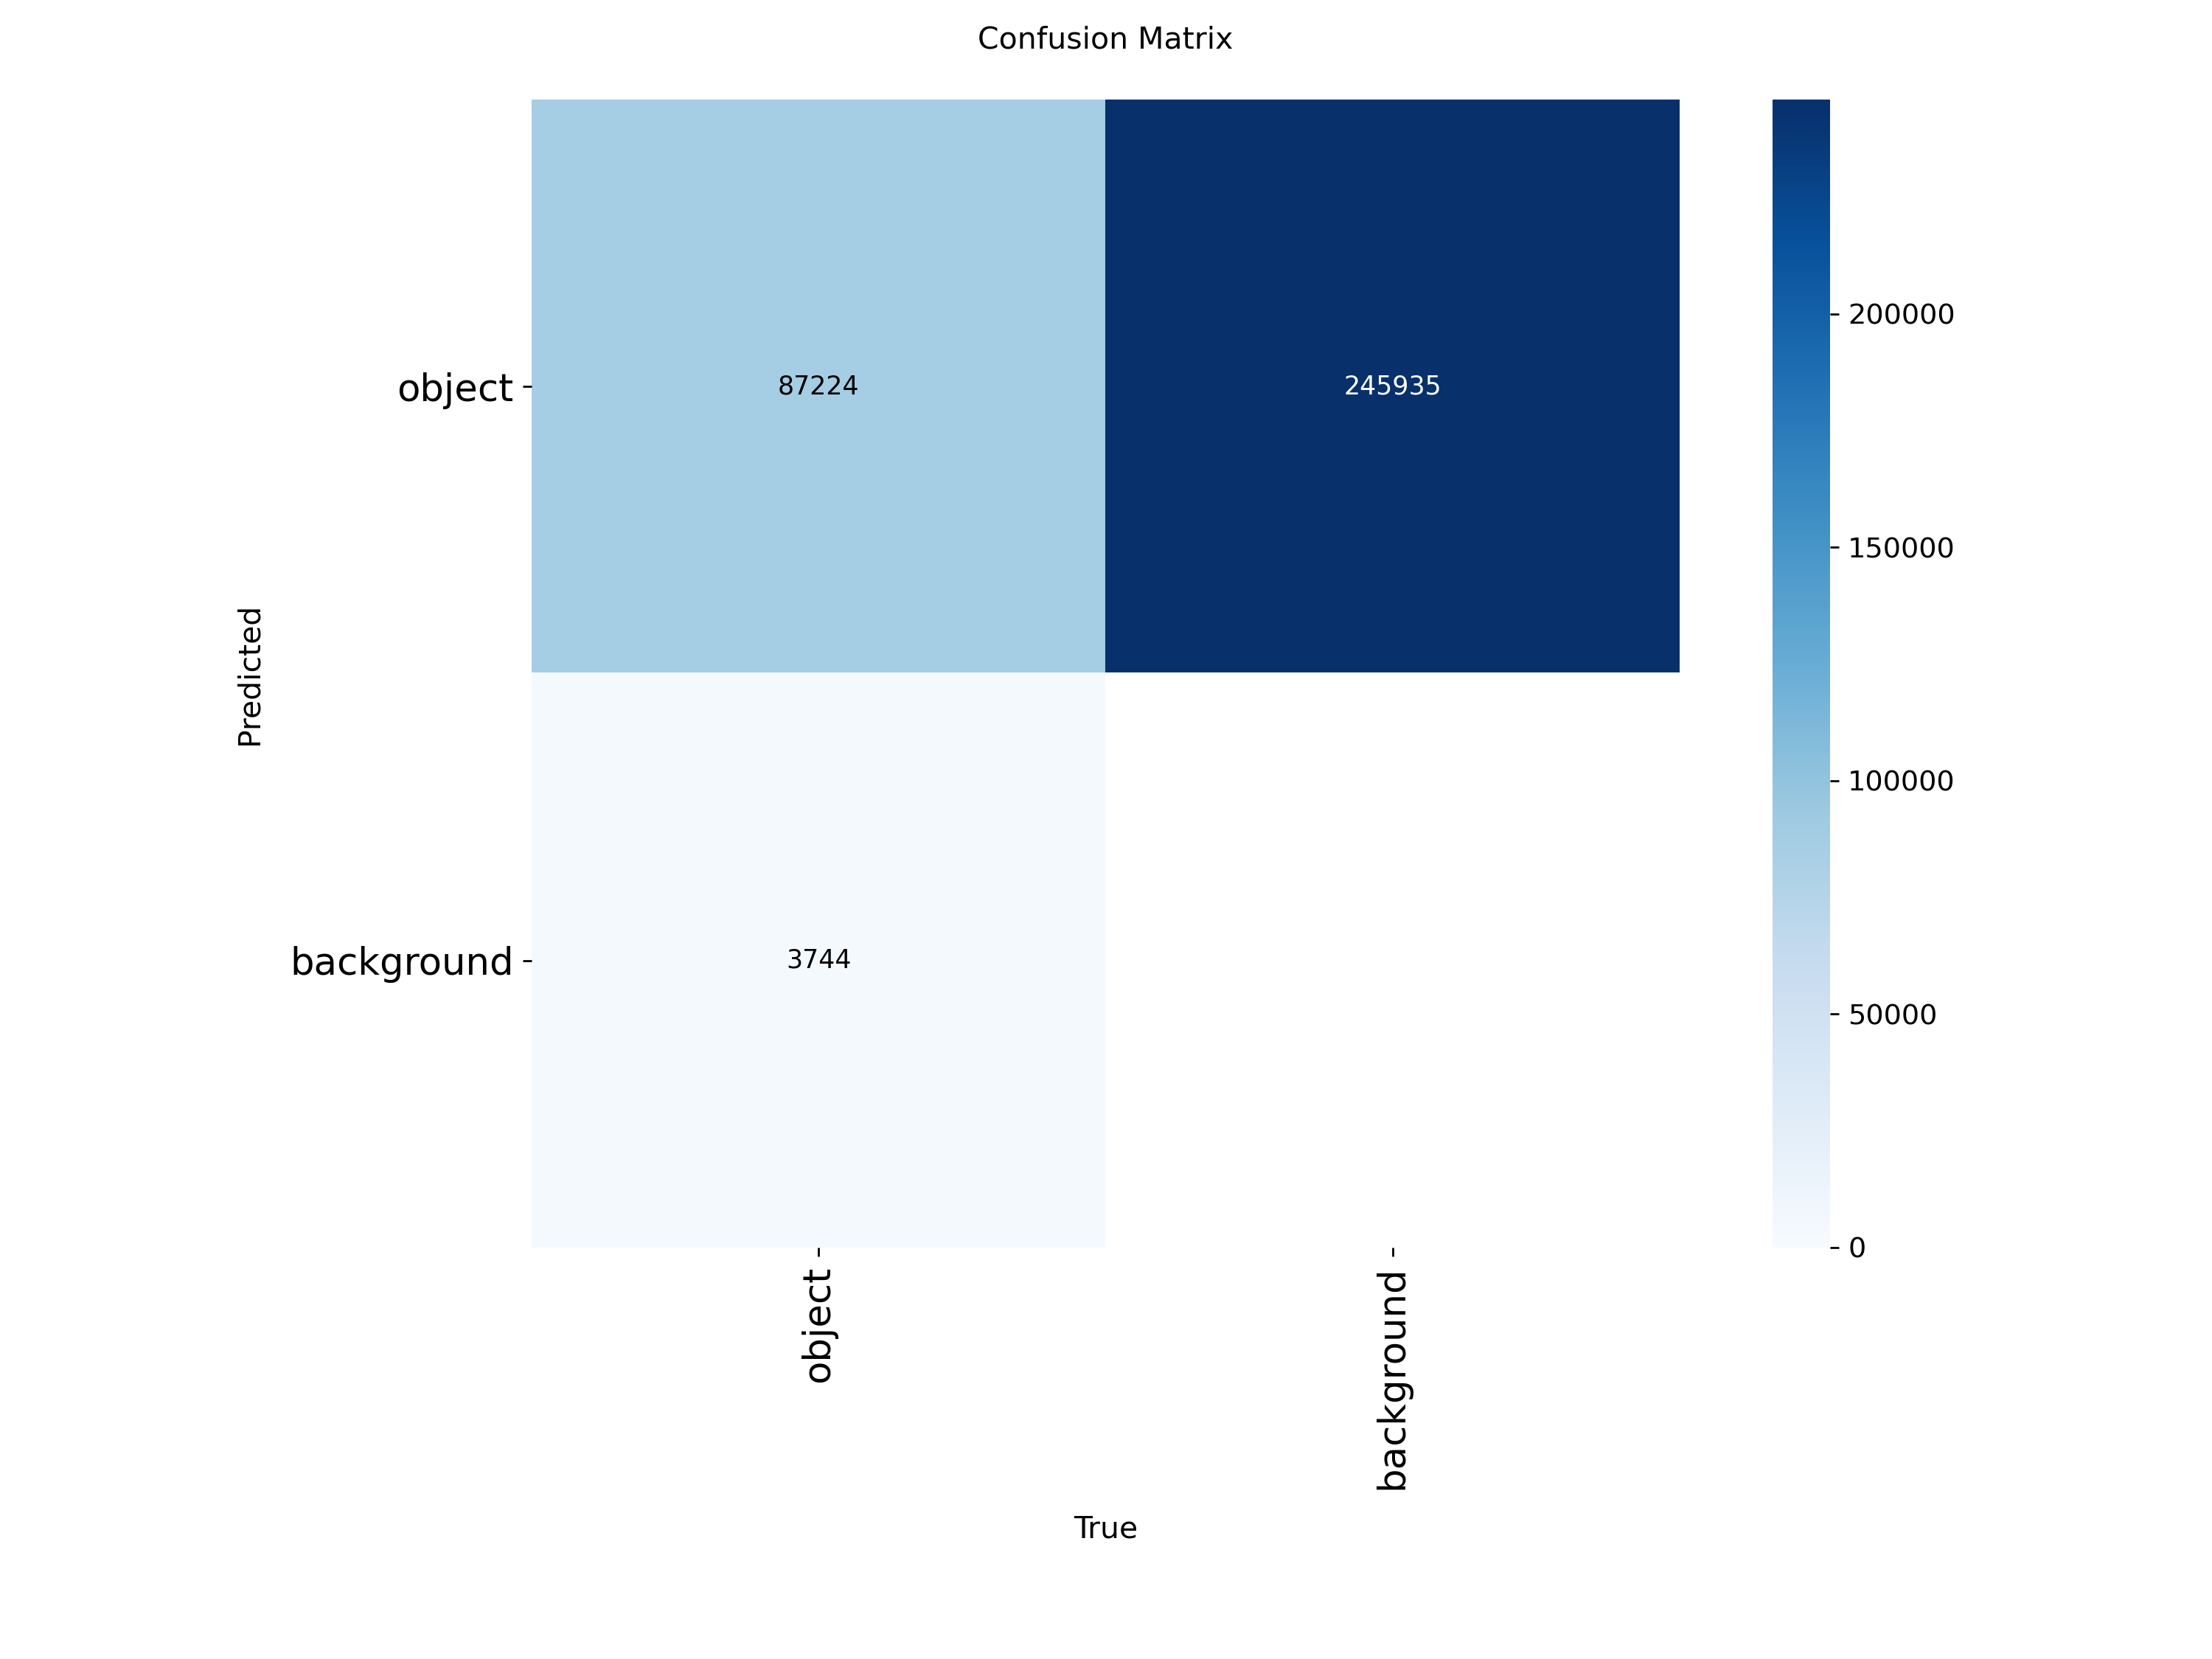

=== Empty-space detector — best epoch 24 ===
mAP@0.5      : 0.591
mAP@0.5:0.95 : 0.251
Precision    : 0.603
Recall       : 0.581

results.png


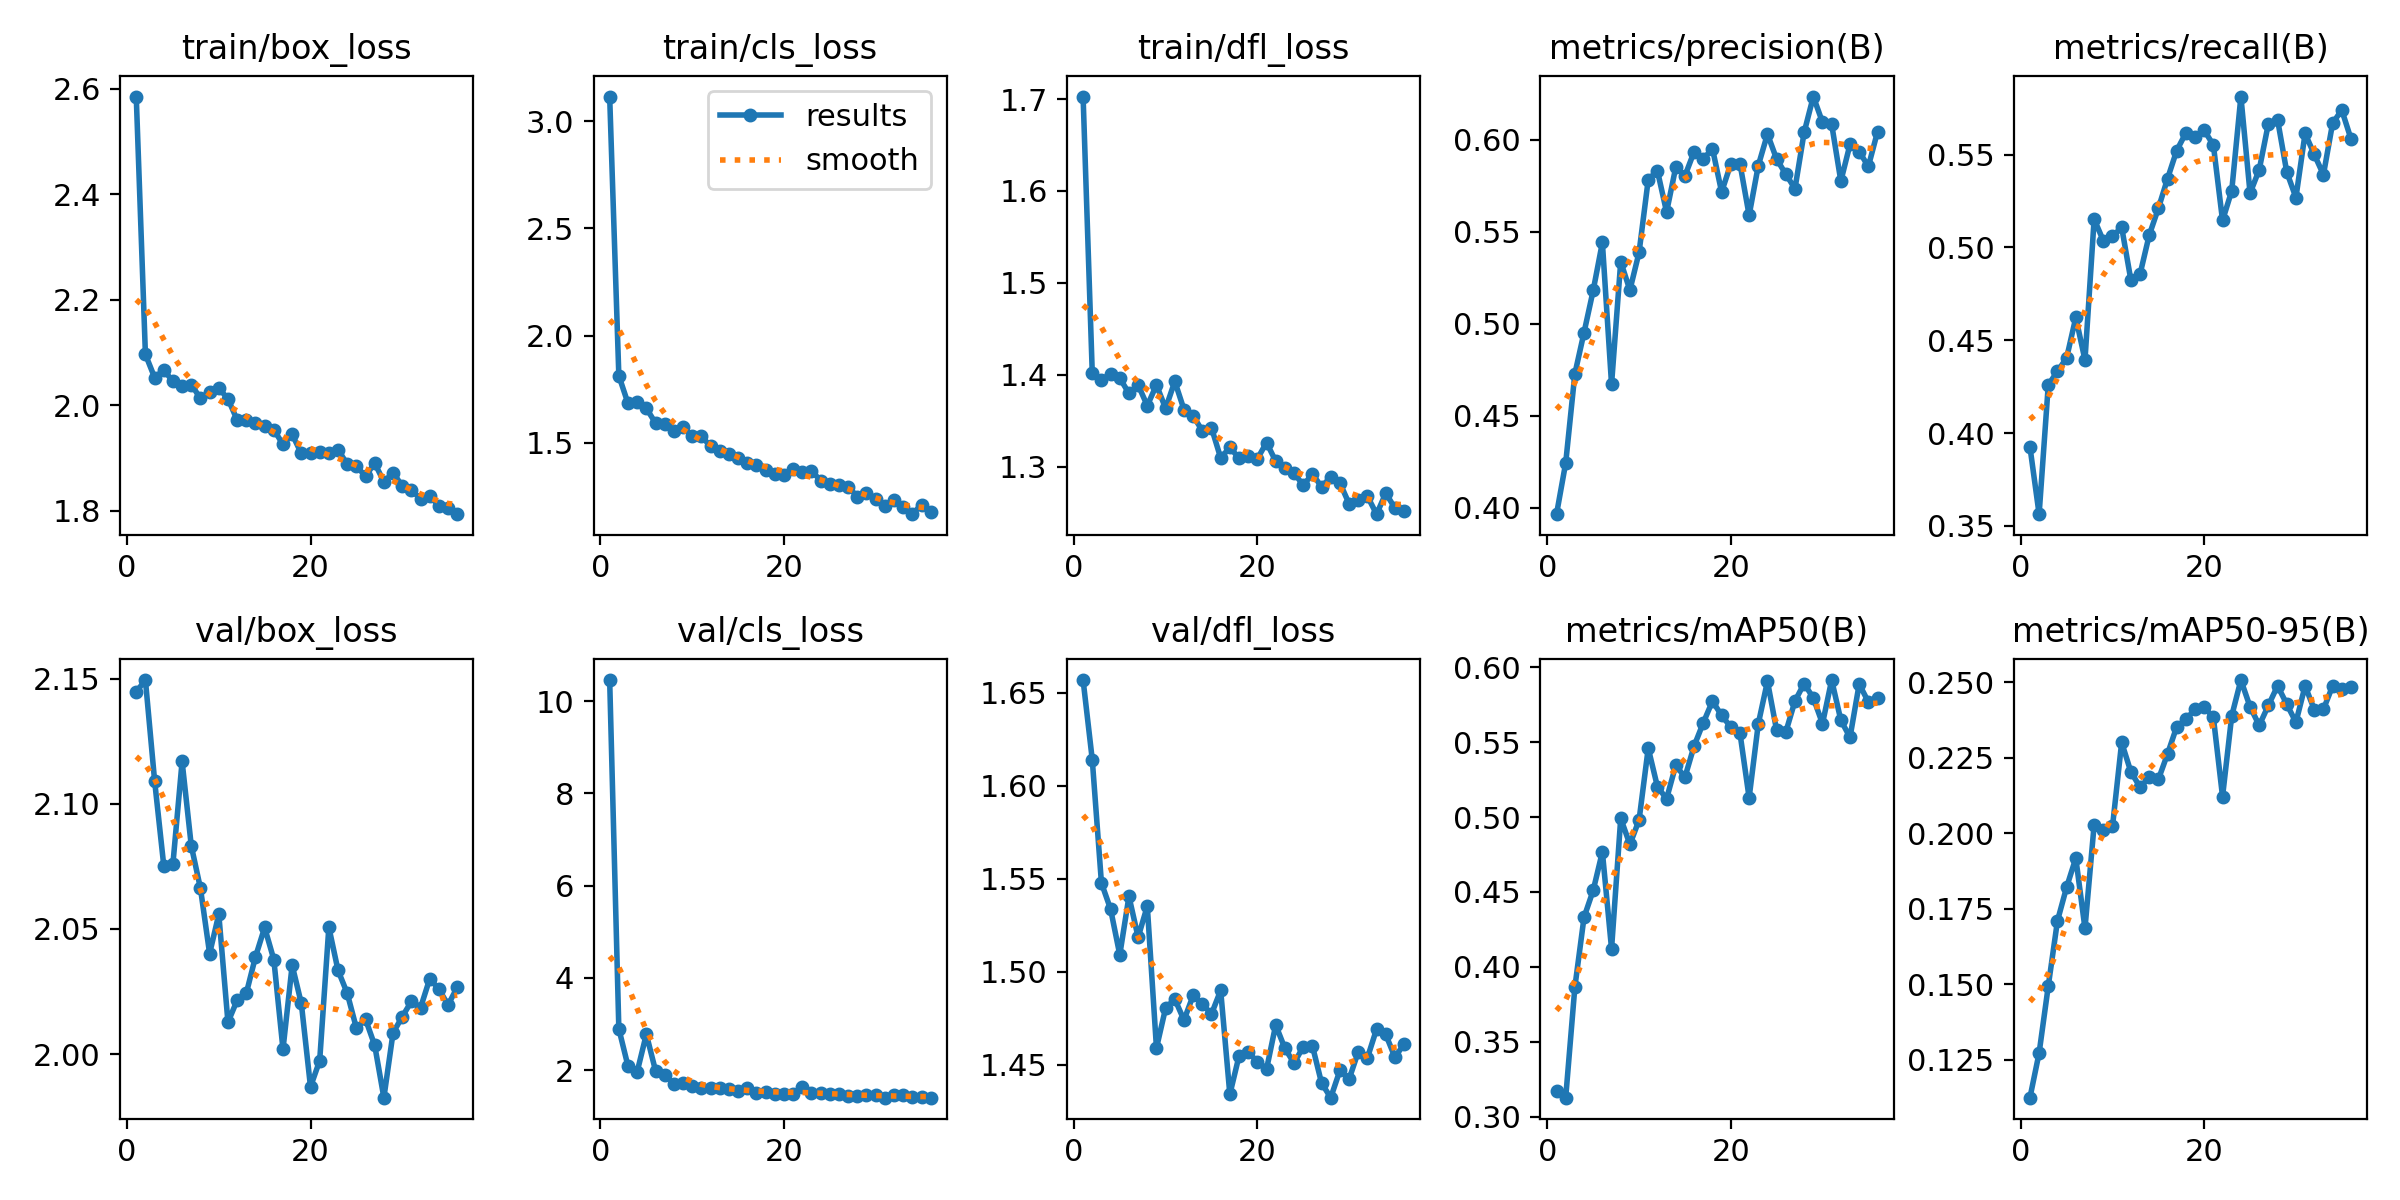

confusion_matrix.png


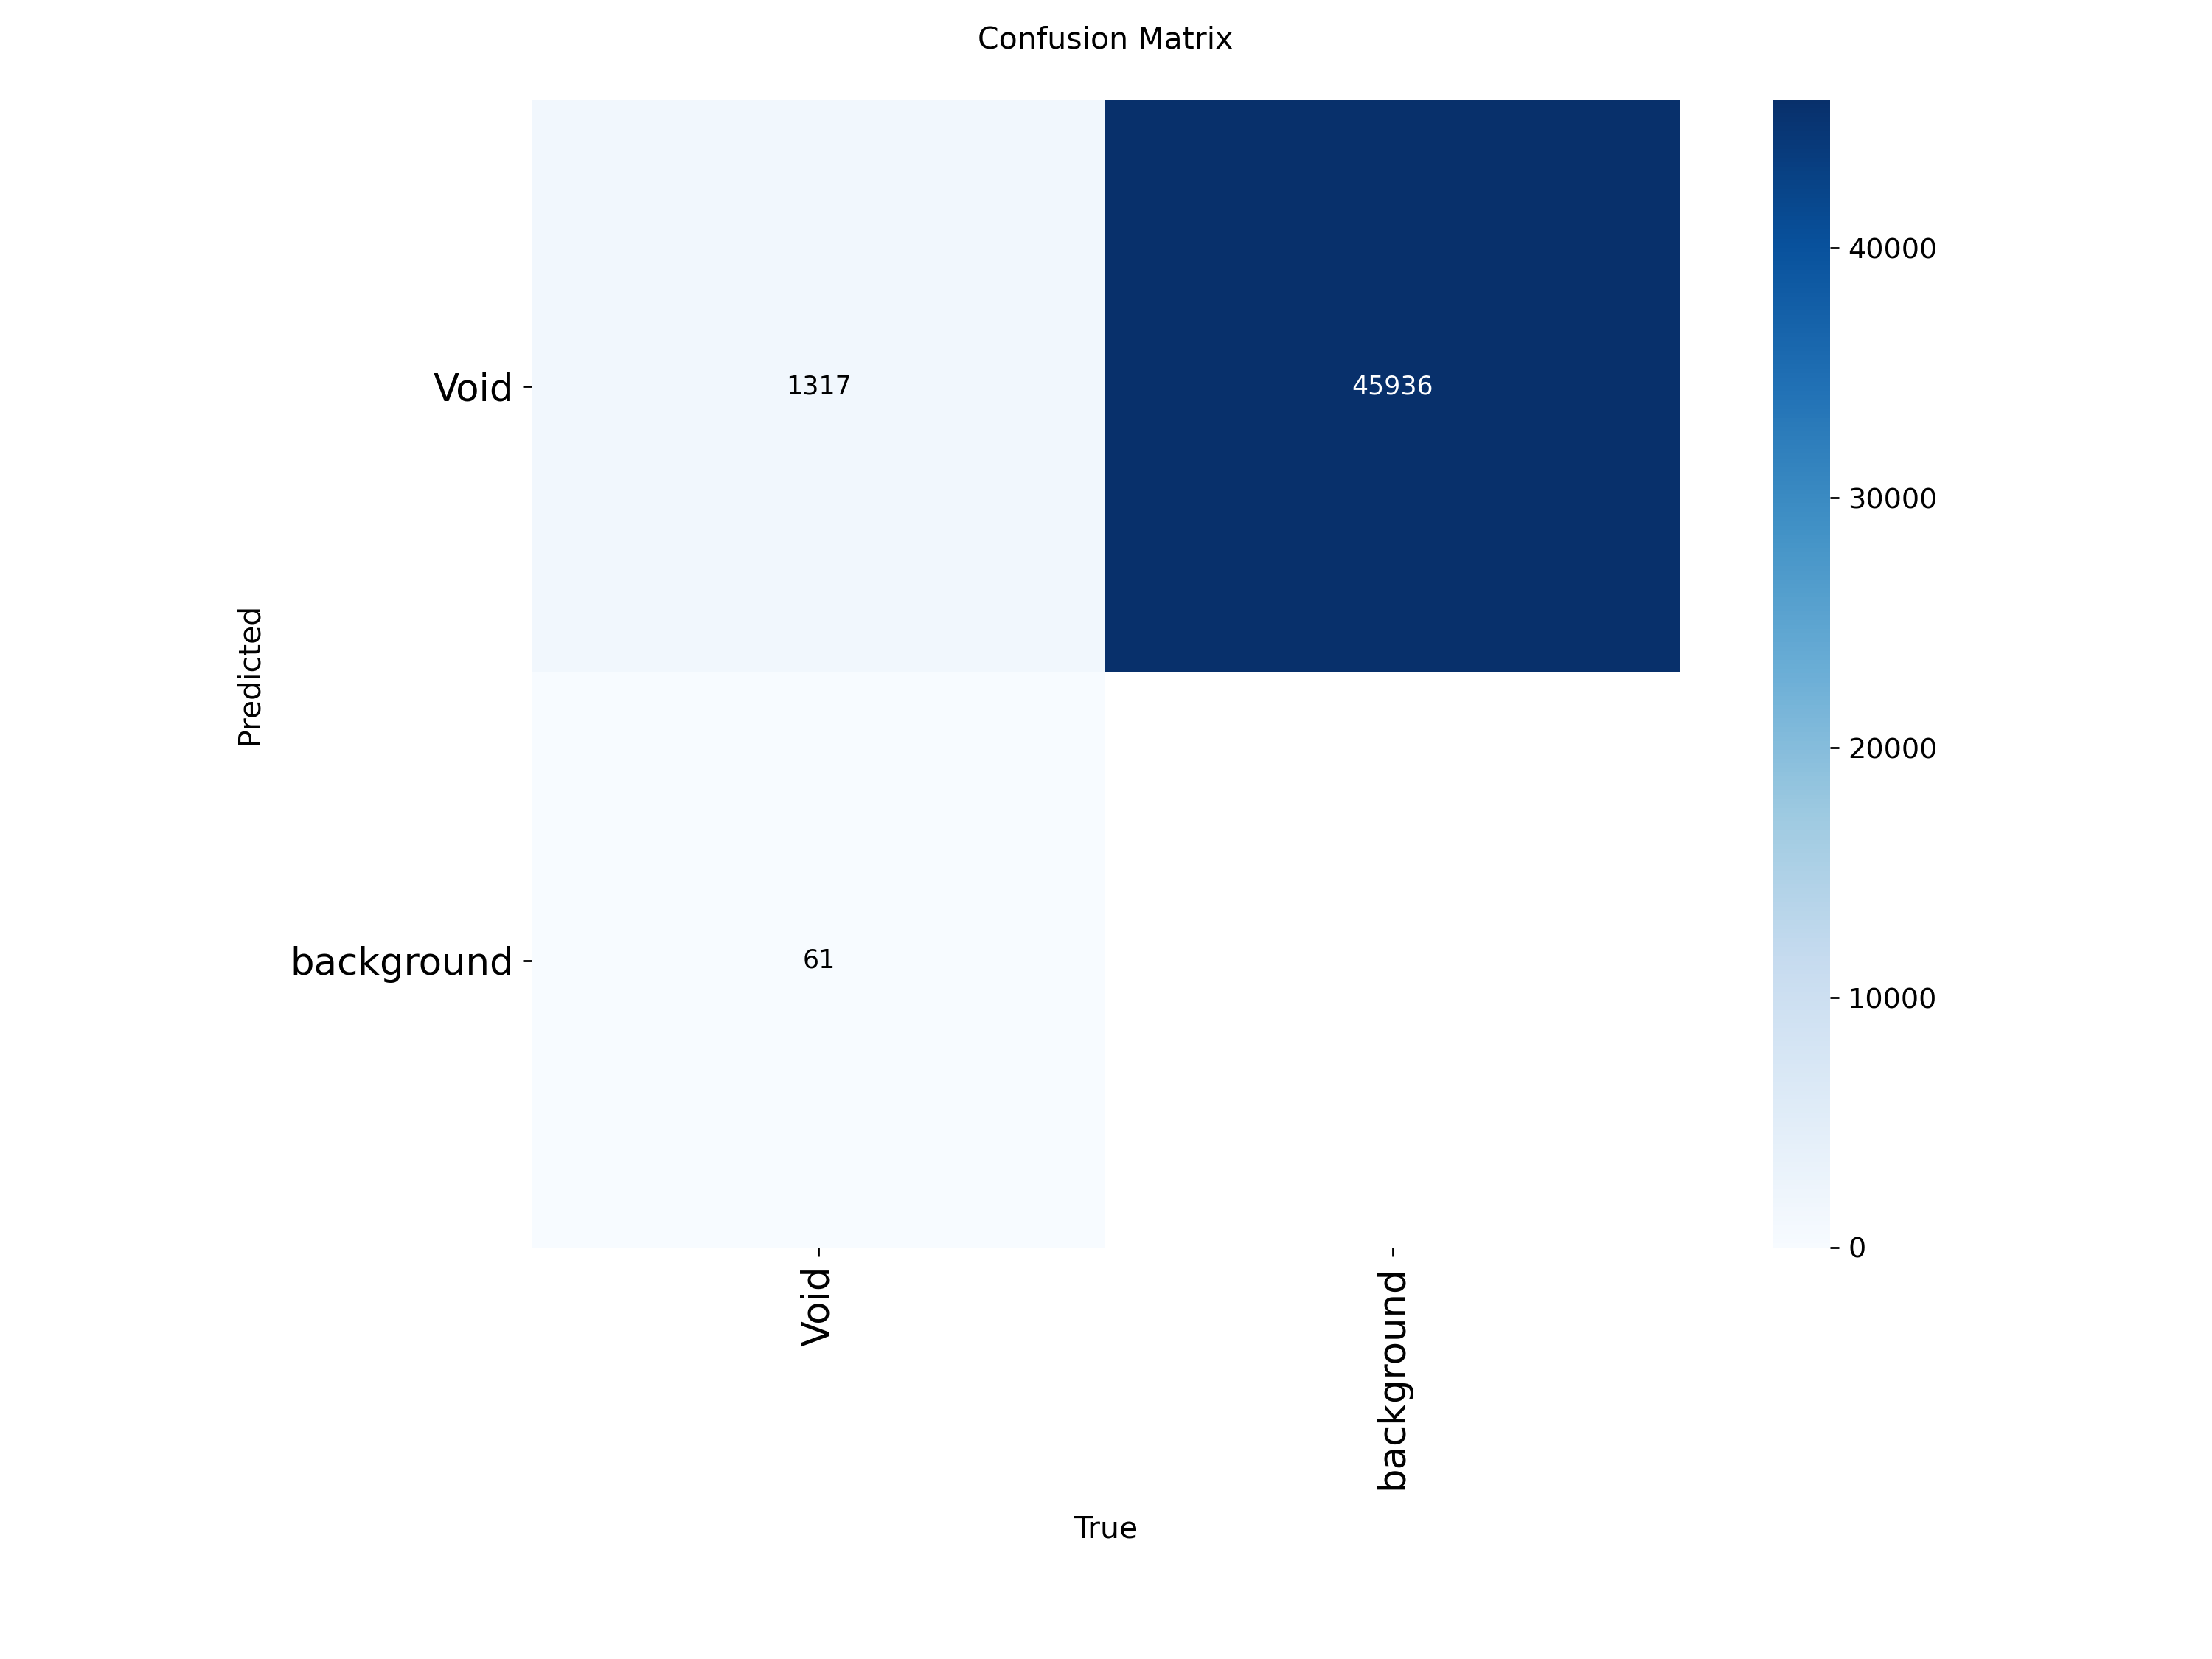

In [ ]:
import pandas as pd
from IPython.display import Image, display

for name, d in [("Product detector (SKU-110K)", PROD_DIR), ("Empty-space detector", EMPTY_DIR)]:
    df = pd.read_csv(f"{d}/results.csv")
    df.columns = df.columns.str.strip()
    best = df.loc[df["metrics/mAP50-95(B)"].idxmax()]
    print(f"=== {name} — best epoch {int(best['epoch'])} ===")
    print(f"mAP@0.5      : {best['metrics/mAP50(B)']:.3f}")
    print(f"mAP@0.5:0.95 : {best['metrics/mAP50-95(B)']:.3f}")
    print(f"Precision    : {best['metrics/precision(B)']:.3f}")
    print(f"Recall       : {best['metrics/recall(B)']:.3f}\n")

    for f in ["results.png", "confusion_matrix.png", "PR_curve.png"]:
        p = f"{d}/{f}"
        if os.path.exists(p):
            print(f); display(Image(p, width=850))

## 5. ShelfSense analysis (both models combined)
- Products → green boxes, Empty space → red boxes
- Empty boxes that mostly overlap a product are discarded (reduces false alarms)
- **Shelf occupancy % = product area / (product area + empty area)**
- Status: ≥ 90 % → Fully stocked · 60–90 % → Partially stocked · < 60 % → Restock urgently

In [ ]:
def overlap_ratio(e, p):
    """Fraction of empty box e covered by product box p."""
    ix = max(0, min(e[2], p[2]) - max(e[0], p[0]))
    iy = max(0, min(e[3], p[3]) - max(e[1], p[1]))
    return ix * iy / max(1, (e[2] - e[0]) * (e[3] - e[1]))

def area(b): return max(0, b[2] - b[0]) * max(0, b[3] - b[1])

def analyse_shelf(image_bgr, prod_conf=0.30, empty_conf=0.35):
    h, w = image_bgr.shape[:2]
    pr = prod_model.predict(image_bgr, conf=prod_conf, imgsz=640, max_det=500, verbose=False)[0]
    er = empty_model.predict(image_bgr, conf=empty_conf, imgsz=640, verbose=False)[0]
    pboxes = pr.boxes.xyxy.cpu().numpy().astype(int)
    eboxes = [e for e in er.boxes.xyxy.cpu().numpy().astype(int)
              if all(overlap_ratio(e, p) < 0.5 for p in pboxes)]

    out = image_bgr.copy()
    lw = max(2, int(min(h, w) / 400))
    for x1, y1, x2, y2 in pboxes:
        cv2.rectangle(out, (x1, y1), (x2, y2), (60, 200, 60), lw)
    for x1, y1, x2, y2 in eboxes:
        ov = out.copy(); cv2.rectangle(ov, (x1, y1), (x2, y2), (0, 0, 255), -1)
        out = cv2.addWeighted(ov, 0.35, out, 0.65, 0)
        cv2.rectangle(out, (x1, y1), (x2, y2), (0, 0, 255), lw + 1)
        cv2.putText(out, "EMPTY", (x1 + 5, y1 + 30), cv2.FONT_HERSHEY_SIMPLEX, max(0.7, w / 1200), (0, 0, 255), lw)

    p_area = sum(area(b) for b in pboxes)
    e_area = sum(area(b) for b in eboxes)
    occupancy = 100 * p_area / max(1, p_area + e_area)
    if occupancy >= 90:   status = "✅ Fully stocked"
    elif occupancy >= 60: status = "🟡 Partially stocked"
    else:                 status = "🔴 Restock urgently"
    report = {
        "products_detected": len(pboxes),
        "empty_slots": len(eboxes),
        "empty_area_%_of_image": round(float(100 * e_area / (h * w)), 1),
        "shelf_occupancy_%": round(float(occupancy), 1),
        "status": status,
    }

    banner = f"{status[2:]} | Products: {len(pboxes)} | Empty: {len(eboxes)} | Occupancy: {occupancy:.0f}%"
    cv2.rectangle(out, (0, 0), (w, int(h * 0.05) + 10), (30, 30, 30), -1)
    cv2.putText(out, banner, (10, int(h * 0.04)), cv2.FONT_HERSHEY_SIMPLEX, max(0.6, w / 1400), (255, 255, 255), lw)
    return out, report

def show(img_bgr, rep):
    plt.figure(figsize=(12, 10)); plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()
    print(rep)

In [ ]:
# Test on SKU-110K test images
tests = glob.glob("/content/datasets/SKU-110K/images/test/*.jpg") or glob.glob("/content/**/SKU-110K/images/test/*.jpg", recursive=True)
for p in random.sample(tests, min(2, len(tests))):
    show(*analyse_shelf(cv2.imread(p)))

Saving test_52_jpg.rf.efe8cdc3e909b69814976555749ce749.jpg to test_52_jpg.rf.efe8cdc3e909b69814976555749ce749.jpg


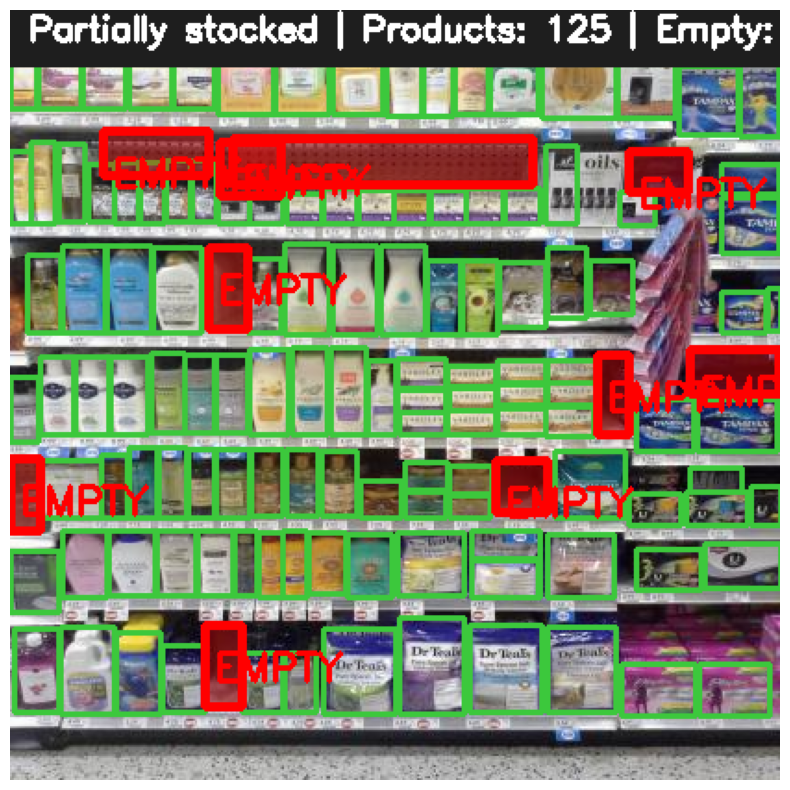

{'products_detected': 125, 'empty_slots': 10, 'empty_area_%_of_image': 7.0, 'shelf_occupancy_%': 87.9, 'status': '🟡 Partially stocked'}


In [ ]:
# Test on your own photos (e.g. empty-shelf photos from the web or a local store)
from google.colab import files
up = files.upload()
for name in up:
    show(*analyse_shelf(cv2.imread(name)))

Classes: {0: 'Void'}
Detections: 27
Confidences: [       0.72        0.64        0.64        0.62         0.6        0.58        0.51        0.49        0.41        0.39        0.22        0.17        0.16        0.14        0.12        0.12        0.12        0.11        0.11         0.1        0.09        0.08        0.08        0.07        0.07        0.06
        0.06]
Class ids: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


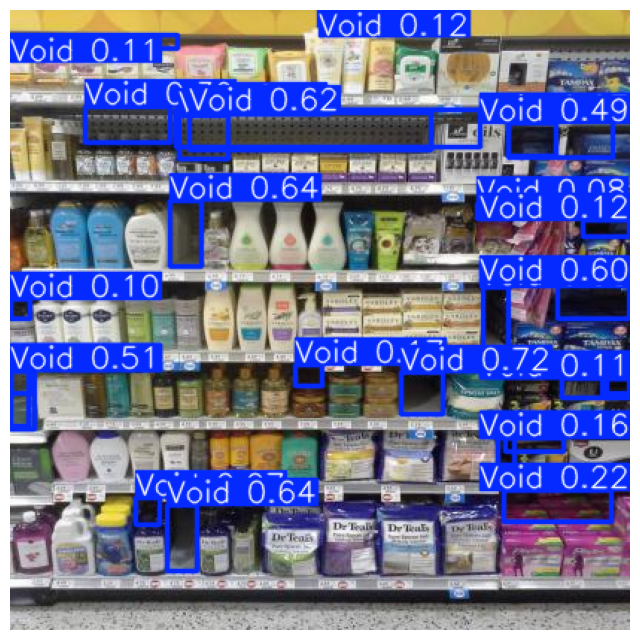

AttributeError: 'float' object has no attribute 'round'

In [ ]:
img = cv2.imread(name)   # same photo
r = empty_model.predict(img, conf=0.05, imgsz=640, verbose=False)[0]
print("Classes:", empty_model.names)
print("Detections:", len(r.boxes))
print("Confidences:", r.boxes.conf.cpu().numpy().round(2))
print("Class ids:", r.boxes.cls.cpu().numpy().astype(int))
plt.figure(figsize=(8, 12)); plt.imshow(r.plot()[:, :, ::-1]); plt.axis("off"); plt.show()

df = pd.read_csv(f"{EMPTY_DIR}/results.csv"); df.columns = df.columns.str.strip()
print("Empty model best mAP@0.5:", df["metrics/mAP50(B)"].max().round(3))

## 6. Gradio demo (public link for presentation)

In [ ]:
import gradio as gr, pandas as pd

def demo_fn(img_rgb, pc, ec):
    out, rep = analyse_shelf(cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR), pc, ec)
    md = (f"## {rep['status']}\n"
          f"**Products:** {rep['products_detected']} &nbsp;|&nbsp; **Empty slots:** {rep['empty_slots']} "
          f"&nbsp;|&nbsp; **Shelf occupancy:** {rep['shelf_occupancy_%']}%")
    table = pd.DataFrame(list(rep.items()), columns=["Metric", "Value"])
    return cv2.cvtColor(out, cv2.COLOR_BGR2RGB), md, table

with gr.Blocks(title="ShelfSense") as app:
    gr.Markdown("# 🛒 ShelfSense — Retail Shelf Product & Empty-Space Detection (YOLOv8)")
    with gr.Row():
        with gr.Column():
            inp = gr.Image(type="numpy", label="Shelf image")
            pc = gr.Slider(0.1, 0.9, 0.30, step=0.05, label="Product confidence")
            ec = gr.Slider(0.1, 0.9, 0.35, step=0.05, label="Empty-space confidence")
            btn = gr.Button("Analyse shelf", variant="primary")
        with gr.Column():
            out = gr.Image(label="Green = product, Red = empty")
            summ = gr.Markdown()
            tab = gr.Dataframe()
    btn.click(demo_fn, [inp, pc, ec], [out, summ, tab])
app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9df289eace71f7c3dc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 7. For the report
- **Limitation found in v1:** domain shift — a bottles-only dataset failed on cartons/cans; gap logic failed on fully empty shelves.
- **Fix in v2:** class-agnostic product detector (SKU-110K) + dedicated empty-space detector.
- Extensions: YOLOv8n vs s vs m comparison, higher `imgsz` (960) for dense shelves, brand classification on product crops.